# IDS - Network Intrusion Detection

Analise Exploratoria e Tratamento de Dados


## 1. Setup - Importacoes


In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, RobustScaler
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from xgboost import XGBClassifier
from sklearn.svm import LinearSVC
from sklearn.neural_network import MLPClassifier
from sklearn.inspection import permutation_importance
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier

pd.set_option('display.max_rows', 100)
pd.set_option('display.max_columns', 100)

BASE = '../datas'
ddos = pd.read_csv(f'{BASE}/raw/DDoS.csv')


## 2. Exploracao dos Dados


In [19]:
print('===== DDOS Dataset =====')
print('Shape:', ddos.shape)
print('\nTipos:\n', ddos.dtypes)


===== DDOS Dataset =====
Shape: (225745, 79)

Tipos:
  Destination Port                 int64
 Flow Duration                    int64
 Total Fwd Packets                int64
 Total Backward Packets           int64
Total Length of Fwd Packets       int64
 Total Length of Bwd Packets      int64
 Fwd Packet Length Max            int64
 Fwd Packet Length Min            int64
 Fwd Packet Length Mean         float64
 Fwd Packet Length Std          float64
Bwd Packet Length Max             int64
 Bwd Packet Length Min            int64
 Bwd Packet Length Mean         float64
 Bwd Packet Length Std          float64
Flow Bytes/s                    float64
 Flow Packets/s                 float64
 Flow IAT Mean                  float64
 Flow IAT Std                   float64
 Flow IAT Max                     int64
 Flow IAT Min                     int64
Fwd IAT Total                     int64
 Fwd IAT Mean                   float64
 Fwd IAT Std                    float64
 Fwd IAT Max              

## 3. Limpeza e Tratamento


In [20]:
ddos.columns = ddos.columns.str.strip()
ddos['Label'] = ddos['Label'].str.strip()

### 3.1 Valores Infinitos


In [21]:
# Converter infinitos em NaN
ddos.replace([np.inf, -np.inf], np.nan, inplace=True)


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Min Packet Length,Max Packet Length,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWE Flag Count,ECE Flag Count,Down/Up Ratio,Average Packet Size,Avg Fwd Segment Size,Avg Bwd Segment Size,Fwd Header Length.1,Fwd Avg Bytes/Bulk,Fwd Avg Packets/Bulk,Fwd Avg Bulk Rate,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk,Bwd Avg Bulk Rate,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init_Win_bytes_forward,Init_Win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,54865,3,2,0,12,0,6,6,6.0,0.0,0,0,0.0,0.0,4.000000e+06,666666.66670,3.0,0.0,3,3,3,3.0,0.0,3,3,0,0.0,0.0,0,0,0,0,0,0,40,0,666666.666700,0.000000,6,6,6.0,0.0,0.0,0,0,0,0,1,0,0,0,0,9.0,6.0,0.0,40,0,0,0,0,0,0,2,12,0,0,33,-1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,55054,109,1,1,6,6,6,6,6.0,0.0,6,6,6.0,0.0,1.100917e+05,18348.62385,109.0,0.0,109,109,0,0.0,0.0,0,0,0,0.0,0.0,0,0,0,0,0,0,20,20,9174.311927,9174.311927,6,6,6.0,0.0,0.0,0,0,0,0,1,1,0,0,1,9.0,6.0,6.0,20,0,0,0,0,0,0,1,6,1,6,29,256,0,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,55055,52,1,1,6,6,6,6,6.0,0.0,6,6,6.0,0.0,2.307692e+05,38461.53846,52.0,0.0,52,52,0,0.0,0.0,0,0,0,0.0,0.0,0,0,0,0,0,0,20,20,19230.769230,19230.769230,6,6,6.0,0.0,0.0,0,0,0,0,1,1,0,0,1,9.0,6.0,6.0,20,0,0,0,0,0,0,1,6,1,6,29,256,0,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,46236,34,1,1,6,6,6,6,6.0,0.0,6,6,6.0,0.0,3.529412e+05,58823.52941,34.0,0.0,34,34,0,0.0,0.0,0,0,0,0.0,0.0,0,0,0,0,0,0,20,20,29411.764710,29411.764710,6,6,6.0,0.0,0.0,0,0,0,0,1,1,0,0,1,9.0,6.0,6.0,20,0,0,0,0,0,0,1,6,1,6,31,329,0,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,54863,3,2,0,12,0,6,6,6.0,0.0,0,0,0.0,0.0,4.000000e+06,666666.66670,3.0,0.0,3,3,3,3.0,0.0,3,3,0,0.0,0.0,0,0,0,0,0,0,40,0,666666.666700,0.000000,6,6,6.0,0.0,0.0,0,0,0,0,1,0,0,0,0,9.0,6.0,0.0,40,0,0,0,0,0,0,2,12,0,0,32,-1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
225740,61374,61,1,1,6,6,6,6,6.0,0.0,6,6,6.0,0.0,1.967213e+05,32786.88525,61.0,0.0,61,61,0,0.0,0.0,0,0,0,0.0,0.0,0,0,0,0,0,0,20,20,16393.442620,16393.442620,6,6,6.0,0.0,0.0,0,0,0,0,1,1,0,0,1,9.0,6.0,6.0,20,0,0,0,0,0,0,1,6,1,6,288,253,0,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
225741,61378,72,1,1,6,6,6,6,6.0,0.0,6,6,6.0,0.0,1.666667e+05,27777.77778,72.0,0.0,72,72,0,0.0,0.0,0,0,0,0.0,0.0,0,0,0,0,0,0,20,20,13888.888890,13888.888890,6,6,6.0,0.0,0.0,0,0,0,0,1,1,0,0,1,9.0,6.0,6.0,20,0,0,0,0,0,0,1,6,1,6,288,253,0,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
225742,61375,75,1,1,6,6,6,6,6.0,0.0,6,6,6.0,0.0,1.600000e+05,26666.66667,75.0,0.0,75,75,0,0.0,0.0,0,0,0,0.0,0.0,0,0,0,0,0,0,20,20,13333.333330,13333.333330,6,6,6.0,0.0,0.0,0,0,0,0,1,1,0,0,1,9.0,6.0,6.0,20,0,0,0,0,0,0,1,6,1,6,288,253,0,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
225743,61323,48,2,0,12,0,6,6,6.0,0.0,0,0,0.0,0.0,2.500000e+05,41666.66667,48.0,0.0,48,48,48,48.0,0.0,48,48,0,0.0,0.0,0,0,0,0,0,0,40,0,41666.666670,0.000000,6,6,6.0,0.0,0.0,0,0,0,0,1,0,0,0,0,9.0,6.0,0.0,40,0,0,0,0,0,0,2,12,0,0,4719,-1,1,20,0.0,0.0,0,0,0.0,0.

### 3.2 Valores Ausentes


In [22]:
print('\nValores ausentes:')
print(ddos.isna().sum())

# Remover NaN em Flow Bytes/s
ddos.dropna(subset=['Flow Bytes/s', 'Flow Bytes/s', 'Flow Packets/s'], inplace=True)




Valores ausentes:
Destination Port                0
Flow Duration                   0
Total Fwd Packets               0
Total Backward Packets          0
Total Length of Fwd Packets     0
Total Length of Bwd Packets     0
Fwd Packet Length Max           0
Fwd Packet Length Min           0
Fwd Packet Length Mean          0
Fwd Packet Length Std           0
Bwd Packet Length Max           0
Bwd Packet Length Min           0
Bwd Packet Length Mean          0
Bwd Packet Length Std           0
Flow Bytes/s                   34
Flow Packets/s                 34
Flow IAT Mean                   0
Flow IAT Std                    0
Flow IAT Max                    0
Flow IAT Min                    0
Fwd IAT Total                   0
Fwd IAT Mean                    0
Fwd IAT Std                     0
Fwd IAT Max                     0
Fwd IAT Min                     0
Bwd IAT Total                   0
Bwd IAT Mean                    0
Bwd IAT Std                     0
Bwd IAT Max                  

### 3.3 Duplicatas


In [23]:
print('Linhas duplicadas:', ddos.duplicated().sum())

ddos.drop_duplicates(inplace=True)


Linhas duplicadas: 2629


### 3.4 Codificacao de Labels


In [24]:

le = LabelEncoder()
ddos['Label'] = le.fit_transform(ddos['Label'])


## 4. Preparacao para Modelagem


In [25]:
X = ddos.drop('Label', axis=1)
y = ddos['Label']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [26]:
scaler = StandardScaler()


X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

pca = PCA(n_components=0.95) 

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Features originais:", X_train.shape[1])
print("Features após PCA:", X_train_pca.shape[1])


Features originais: 78
Features após PCA: 21


## 5. Modelagem


### 5.1 Decision Tree


In [27]:
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)
print('Decision Tree Accuracy:', accuracy_score(y_test, dt.predict(X_test)))


Decision Tree Accuracy: 0.9997758701840106


### 5.2 Random Forest


In [28]:
rf = RandomForestClassifier(n_estimators=15, random_state=42)
rf.fit(X_train, y_train)
print('Random Forest Accuracy:', accuracy_score(y_test, rf.predict(X_test)))


Random Forest Accuracy: 0.9998655221104064


### 5.3 XGBoost


In [29]:
xgb = XGBClassifier(n_estimators=10, random_state=42, verbosity=0)
xgb.fit(X_train, y_train)
print('XGBoost Accuracy:', accuracy_score(y_test, xgb.predict(X_test)))


XGBoost Accuracy: 0.9997086312392137


## Analise Detalhada com Metricas


In [30]:
from sklearn.metrics import confusion_matrix, classification_report

# Decision Tree predictions
dt_pred = dt.predict(X_test)

print('='*50)
print('DECISION TREE - METRICAS')
print('='*50)
print(f'Acuracia: {accuracy_score(y_test, dt_pred):.4f}')
print('\nClassification Report:')
print(classification_report(y_test, dt_pred))


DECISION TREE - METRICAS
Acuracia: 0.9998

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     18954
           1       1.00      1.00      1.00     25663

    accuracy                           1.00     44617
   macro avg       1.00      1.00      1.00     44617
weighted avg       1.00      1.00      1.00     44617



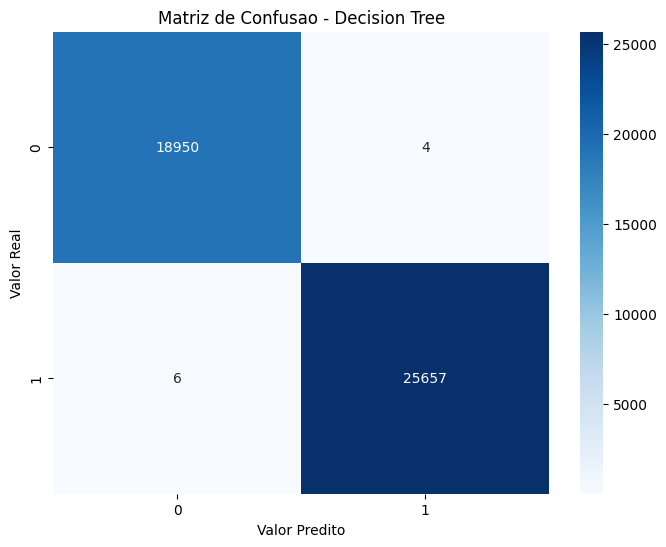

In [31]:
cm_dt = confusion_matrix(y_test, dt_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Blues', cbar=True)
plt.title('Matriz de Confusao - Decision Tree')
plt.ylabel('Valor Real')
plt.xlabel('Valor Predito')
plt.show()


C:\Users\Guilherme Martins\AppData\Local\Temp\ipykernel_18520\2112588436.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feat_dt, x='Importance', y='Feature', palette='viridis')


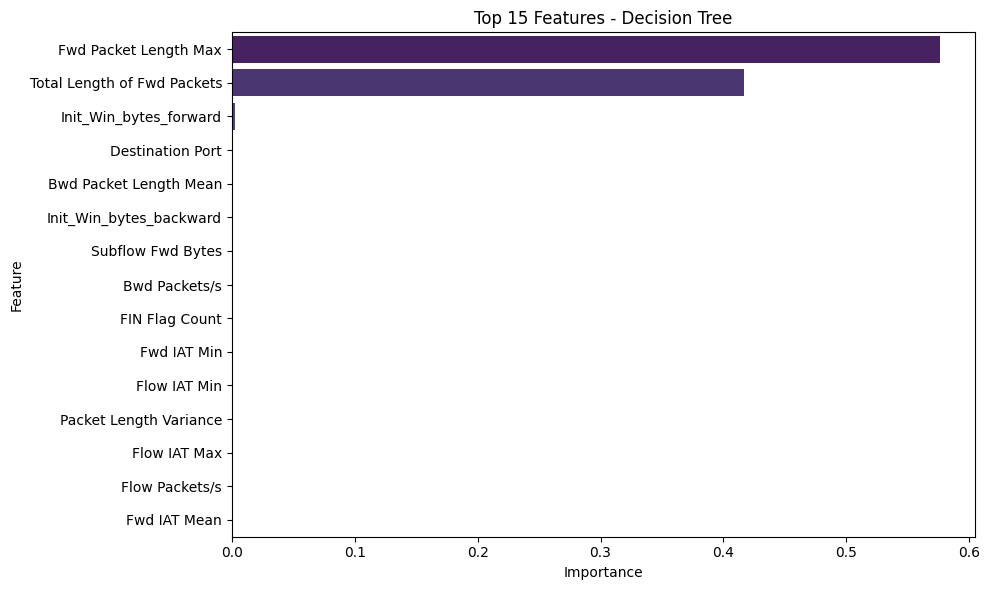

In [32]:
feat_dt = pd.DataFrame({
    'Feature': X.columns,
    'Importance': dt.feature_importances_
}).sort_values('Importance', ascending=False).head(15)

plt.figure(figsize=(10, 6))
sns.barplot(data=feat_dt, x='Importance', y='Feature', palette='viridis')
plt.title('Top 15 Features - Decision Tree')
plt.tight_layout()
plt.show()


In [33]:
rf_pred = rf.predict(X_test)

print('='*50)
print('RANDOM FOREST - METRICAS')
print('='*50)
print(f'Acuracia: {accuracy_score(y_test, rf_pred):.4f}')
print('\nClassification Report:')
print(classification_report(y_test, rf_pred))


RANDOM FOREST - METRICAS
Acuracia: 0.9999

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     18954
           1       1.00      1.00      1.00     25663

    accuracy                           1.00     44617
   macro avg       1.00      1.00      1.00     44617
weighted avg       1.00      1.00      1.00     44617



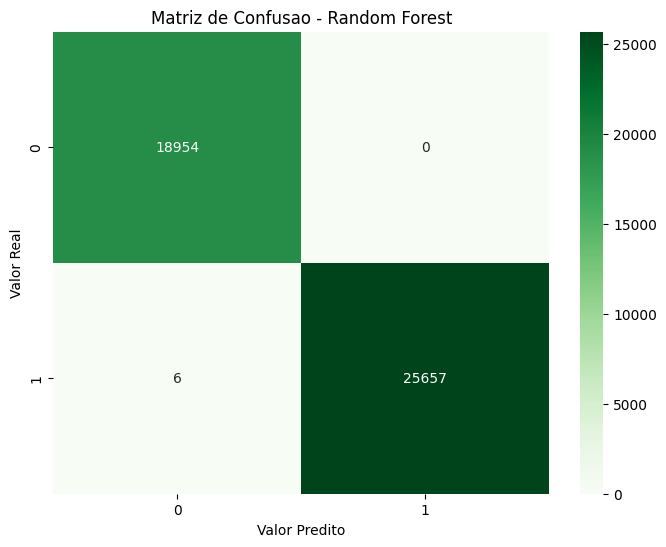

In [34]:
cm_rf = confusion_matrix(y_test, rf_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens', cbar=True)
plt.title('Matriz de Confusao - Random Forest')
plt.ylabel('Valor Real')
plt.xlabel('Valor Predito')
plt.show()


C:\Users\Guilherme Martins\AppData\Local\Temp\ipykernel_18520\2254361004.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feat_rf, x='Importance', y='Feature', palette='rocket')


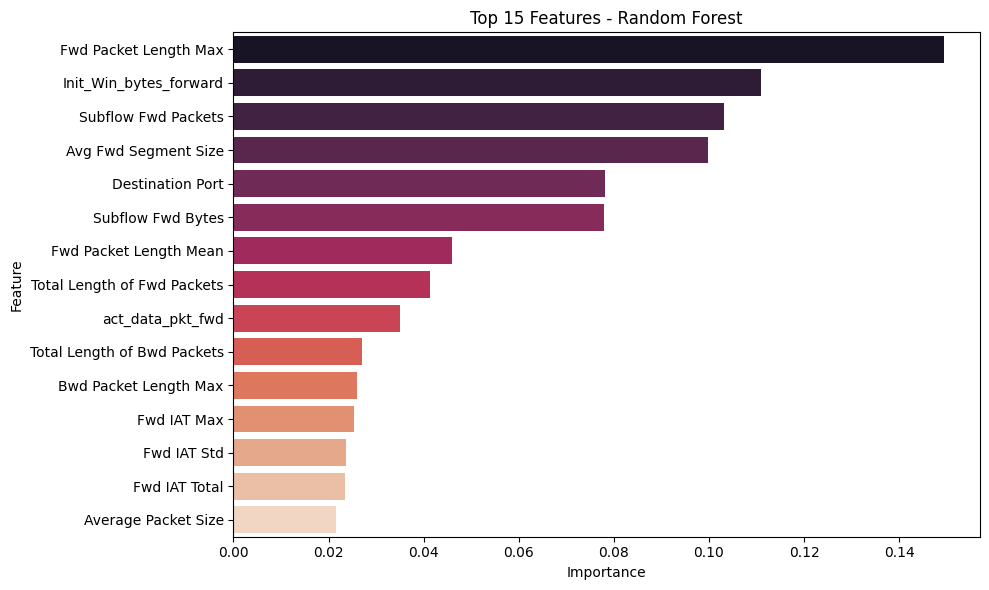

In [36]:
feat_rf = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf.feature_importances_
}).sort_values('Importance', ascending=False).head(15)

plt.figure(figsize=(10, 6))
sns.barplot(data=feat_rf, x='Importance', y='Feature', palette='rocket')
plt.title('Top 15 Features - Random Forest')
plt.tight_layout()
plt.show()


In [37]:
xgb_pred = xgb.predict(X_test)

print('='*50)
print('XGBOOST - METRICAS')
print('='*50)
print(f'Acuracia: {accuracy_score(y_test, xgb_pred):.4f}')
print('\nClassification Report:')
print(classification_report(y_test, xgb_pred))


XGBOOST - METRICAS
Acuracia: 0.9997

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     18954
           1       1.00      1.00      1.00     25663

    accuracy                           1.00     44617
   macro avg       1.00      1.00      1.00     44617
weighted avg       1.00      1.00      1.00     44617



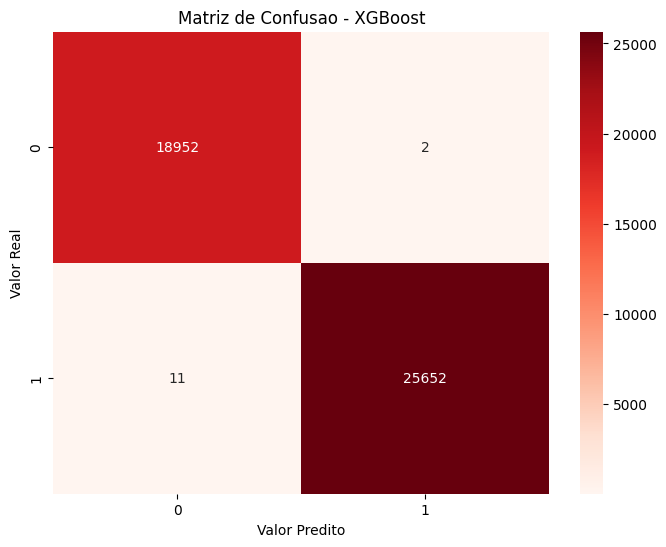

In [38]:
cm_xgb = confusion_matrix(y_test, xgb_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Reds', cbar=True)
plt.title('Matriz de Confusao - XGBoost')
plt.ylabel('Valor Real')
plt.xlabel('Valor Predito')
plt.show()


C:\Users\Guilherme Martins\AppData\Local\Temp\ipykernel_18520\2396377396.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feat_xgb, x='Importance', y='Feature', palette='mako')


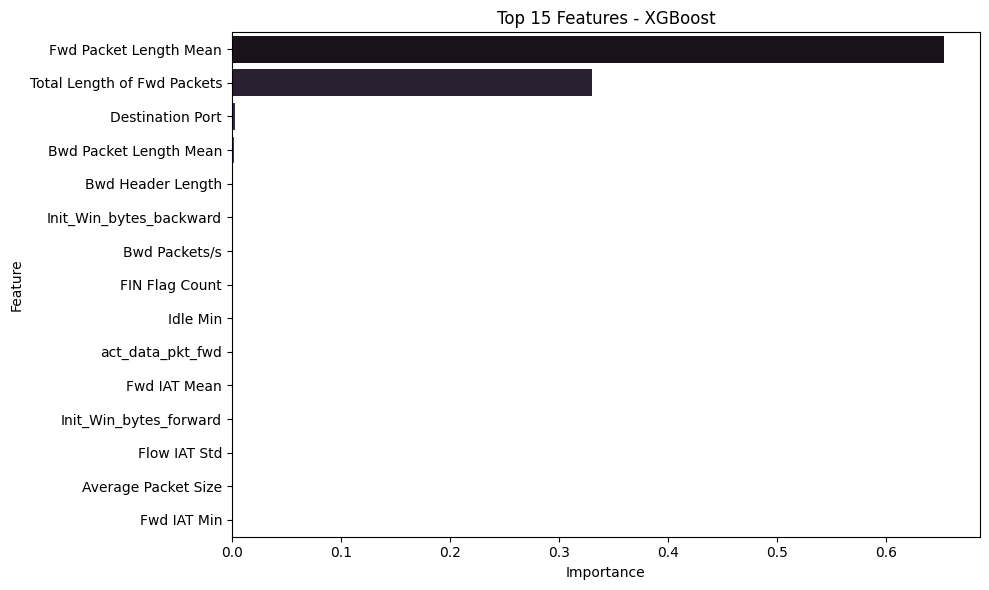

In [39]:
feat_xgb = pd.DataFrame({
    'Feature': X.columns,
    'Importance': xgb.feature_importances_
}).sort_values('Importance', ascending=False).head(15)

plt.figure(figsize=(10, 6))
sns.barplot(data=feat_xgb, x='Importance', y='Feature', palette='mako')
plt.title('Top 15 Features - XGBoost')
plt.tight_layout()
plt.show()


## SVM - Support Vector Machine


In [40]:
# Treinar SVM Linear (mais rápido)
svm = LinearSVC(random_state=42, C=1.0, max_iter=10000)
svm.fit(X_train, y_train)
svm_pred = svm.predict(X_test)

print('='*50)
print('SVM Linear - METRICAS')
print('='*50)
print(f'Acuracia: {accuracy_score(y_test, svm_pred):.4f}')
print('\nClassification Report:')
print(classification_report(y_test, svm_pred))

SVM Linear - METRICAS
Acuracia: 0.9673

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.94      0.96     18954
           1       0.95      0.99      0.97     25663

    accuracy                           0.97     44617
   macro avg       0.97      0.96      0.97     44617
weighted avg       0.97      0.97      0.97     44617



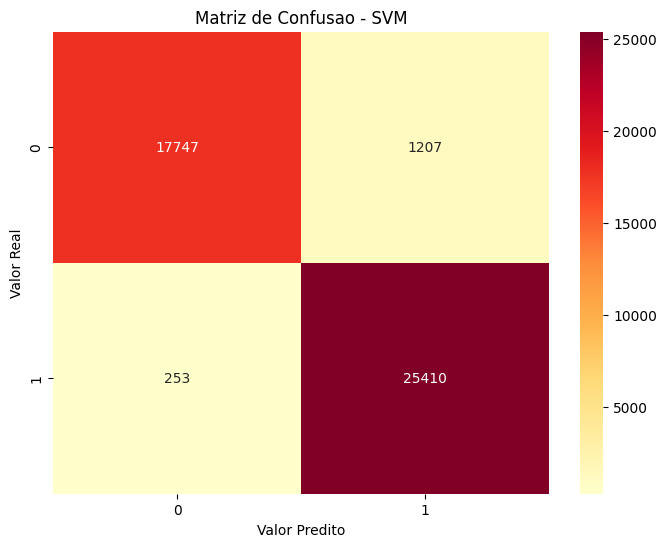

In [41]:
cm_svm = confusion_matrix(y_test, svm_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_svm, annot=True, fmt='d', cmap='YlOrRd', cbar=True)
plt.title('Matriz de Confusao - SVM')
plt.ylabel('Valor Real')
plt.xlabel('Valor Predito')
plt.show()


C:\Users\Guilherme Martins\AppData\Local\Temp\ipykernel_18520\2768230129.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feat_svm, x='Importance', y='Feature', palette='coolwarm')


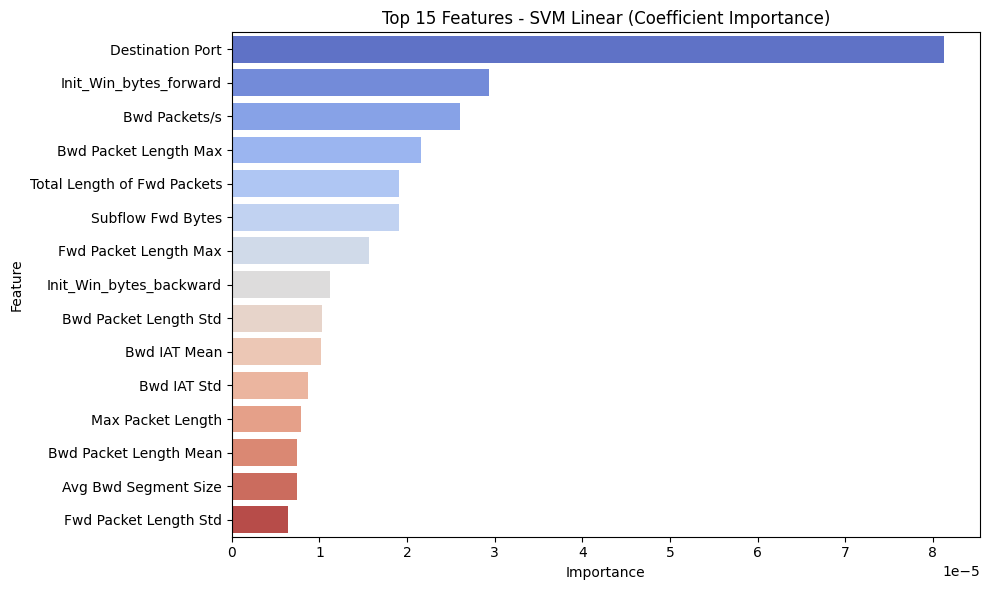

In [42]:
# Para SVM Linear, usar coeficientes absolutos para importância de features
feat_svm = pd.DataFrame({
    'Feature': X.columns,
    'Importance': np.abs(svm.coef_[0])  # coef_[0] para binário, mas verificar se multiclass
}).sort_values('Importance', ascending=False).head(15)

plt.figure(figsize=(10, 6))
sns.barplot(data=feat_svm, x='Importance', y='Feature', palette='coolwarm')
plt.title('Top 15 Features - SVM Linear (Coefficient Importance)')
plt.tight_layout()
plt.show()

## MLP (Multilayer Perceptron)

In [43]:
# Treinar MLP
mlp = MLPClassifier(hidden_layer_sizes=(100, 50), max_iter=500, random_state=42, early_stopping=True)
mlp.fit(X_train, y_train)
mlp_pred = mlp.predict(X_test)

print('='*50)
print('MLP - METRICAS')
print('='*50)
print(f'Acuracia: {accuracy_score(y_test, mlp_pred):.4f}')
print('\nClassification Report:')
print(classification_report(y_test, mlp_pred))

MLP - METRICAS
Acuracia: 0.9968

Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      1.00     18954
           1       1.00      1.00      1.00     25663

    accuracy                           1.00     44617
   macro avg       1.00      1.00      1.00     44617
weighted avg       1.00      1.00      1.00     44617



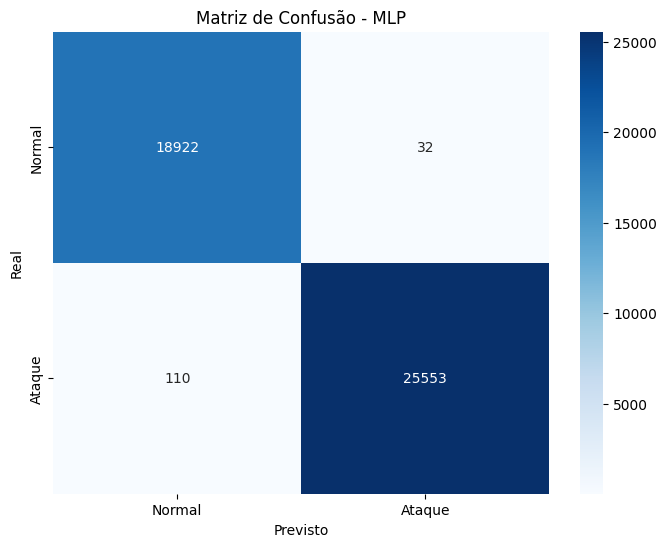

In [ ]:
# Matriz de Confusão - MLP
cm_mlp = confusion_matrix(y_test, mlp_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_mlp, annot=True, fmt='d', cmap='Blues', xticklabels=['Normal', 'Ataque'], yticklabels=['Normal', 'Ataque'])
plt.title('Matriz de Confusão - MLP')
plt.ylabel('Real')
plt.xlabel('Previsto')
plt.show()

C:\Users\Guilherme Martins\AppData\Local\Temp\ipykernel_18520\2177431040.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feat_mlp, x='Importance', y='Feature', palette='coolwarm')


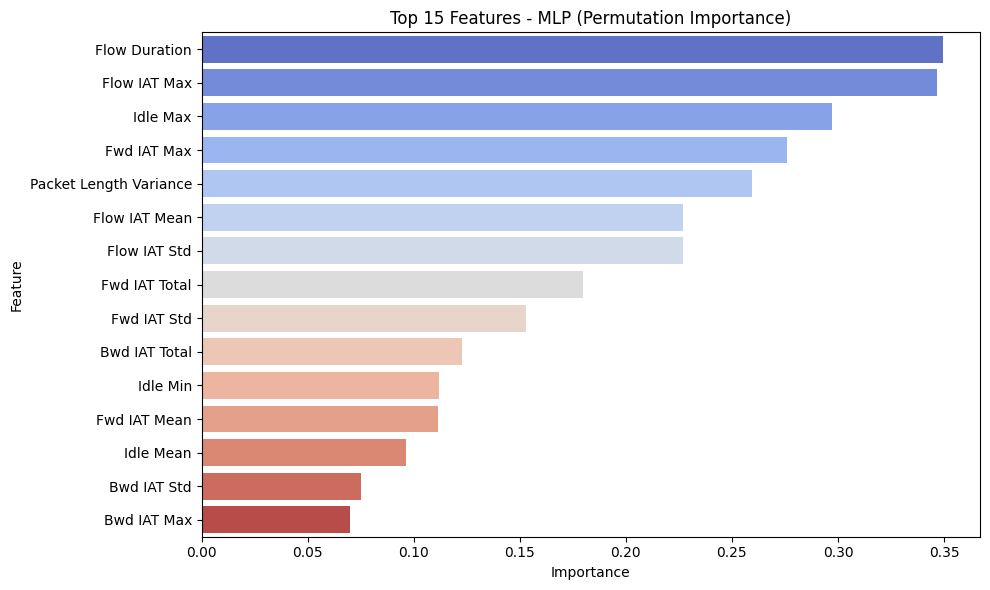

In [44]:
# Calcular importância de features com permutation importance - MLP
perm_importance_mlp = permutation_importance(mlp, X_test, y_test, n_repeats=10, random_state=42)

feat_mlp = pd.DataFrame({
    'Feature': X.columns,
    'Importance': perm_importance_mlp.importances_mean
}).sort_values('Importance', ascending=False).head(15)

plt.figure(figsize=(10, 6))
sns.barplot(data=feat_mlp, x='Importance', y='Feature', palette='coolwarm')
plt.title('Top 15 Features - MLP (Permutation Importance)')
plt.tight_layout()
plt.show()

## Comparacao Final - Todos os Modelos


In [ ]:
# Comparar todos os modelos
resultados = pd.DataFrame({
    'Modelo': ['Decision Tree', 'Random Forest', 'XGBoost', 'SVM', 'MLP'],
    'Acuracia': [
        accuracy_score(y_test, dt_pred),
        accuracy_score(y_test, rf_pred),
        accuracy_score(y_test, xgb_pred),
        accuracy_score(y_test, svm_pred),
        accuracy_score(y_test, mlp_pred)
    ]
})

print('\n' + '='*50)
print('COMPARACAO FINAL - TODOS OS MODELOS')
print('='*50)
print(resultados.to_string(index=False))
print(f'\nMelhor Modelo: {resultados.loc[resultados["Acuracia"].idxmax(), "Modelo"]}')
print('='*50)



COMPARACAO FINAL - TODOS OS MODELOS
       Modelo  Acuracia
Decision Tree  0.999843
Random Forest  0.999965
      XGBoost  0.999895
          SVM  0.950262
          MLP  0.998095

Melhor Modelo: Random Forest


In [ ]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (228876, 78)
X_test shape: (57220, 78)
y_train shape: (228876,)
y_test shape: (57220,)
